# Sistema inteligente de recomendação de culturas agrícolas

Projeto final de Machine Learning. Grupo: Miguel Torres e Mateo Zapelini.

Este notebook executa o projeto completo: análise exploratória, pré-processamento, SVM, árvore de decisão, ensembles (Random Forest e Gradient Boosting) e K-means. Dataset: Crop Recommendation Dataset (Kaggle), arquivo `dados/Crop_recommendation.csv`.

Para rodar no Google Colab, envie a pasta do projeto (com `comum.py` e `dados/`) e execute as células em ordem.

## 0. Ambiente

Versões usadas nos resultados do relatório: Python 3.13, numpy 2.5.3, pandas 3.0.5, scikit-learn 1.9.1, matplotlib 3.11.2.

In [1]:
import sys, sklearn, pandas, numpy, matplotlib
print(sys.version.split()[0], '| sklearn', sklearn.__version__, '| pandas', pandas.__version__, '| numpy', numpy.__version__)
from IPython.display import Image, display

3.13.18 | sklearn 1.9.1 | pandas 3.0.5 | numpy 2.5.3


## 1. Funções comuns

Leitura do CSV, tradução das colunas e das culturas e engenharia de atributos.

In [2]:
"""Configurações compartilhadas pelos scripts do projeto."""

from pathlib import Path  # Caminhos de arquivos.
import pandas as pd  # Leitura da tabela.

# Pasta do projeto: a do arquivo, ou a pasta atual quando rodado no notebook.
PASTA = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
SAIDA = PASTA / "resultados"  # Tabelas e figuras geradas.
SAIDA.mkdir(exist_ok=True)  # Cria a pasta se ainda não existir.
SEMENTE = 42  # Semente fixa para todos os sorteios.

# Nomes das colunas em português, para facilitar a leitura do relatório.
COLUNAS = {"N": "nitrogenio", "P": "fosforo", "K": "potassio",
           "temperature": "temperatura_c", "humidity": "umidade_pct",
           "ph": "ph", "rainfall": "chuva_mm", "label": "cultura"}

# Tradução das 22 culturas do dataset.
CULTURAS = {"rice": "arroz", "maize": "milho", "chickpea": "grão-de-bico",
            "kidneybeans": "feijão-roxo", "pigeonpeas": "feijão-guandu",
            "mothbeans": "feijão-mariposa", "mungbean": "feijão-mungo",
            "blackgram": "feijão-preto-urd", "lentil": "lentilha",
            "pomegranate": "romã", "banana": "banana", "mango": "manga",
            "grapes": "uva", "watermelon": "melancia", "muskmelon": "melão",
            "apple": "maçã", "orange": "laranja", "papaya": "mamão",
            "coconut": "coco", "cotton": "algodão", "jute": "juta",
            "coffee": "café"}

ATRIBUTOS = ["nitrogenio", "fosforo", "potassio", "temperatura_c",
             "umidade_pct", "ph", "chuva_mm"]  # Sete entradas originais.


def carregar_dados():
    """Lê o CSV original do Kaggle e traduz colunas e culturas."""
    dados = pd.read_csv(PASTA / "dados" / "Crop_recommendation.csv")
    dados = dados.rename(columns=COLUNAS)  # Colunas em português.
    dados["cultura"] = dados["cultura"].map(CULTURAS)  # Culturas em português.
    return dados


def criar_atributos(tabela):
    """Engenharia de atributos: proporções entre N, P e K.

    O dataset descreve N, P e K como proporções no solo, então as razões
    entre eles podem carregar informação que os valores isolados não mostram.
    """
    nova = tabela.copy()  # Não altera a tabela recebida.
    nova["npk_total"] = nova.nitrogenio + nova.fosforo + nova.potassio
    nova["razao_n_p"] = nova.nitrogenio / (nova.fosforo + 1)  # +1 evita divisão por zero.
    nova["razao_n_k"] = nova.nitrogenio / (nova.potassio + 1)
    nova["razao_p_k"] = nova.fosforo / (nova.potassio + 1)
    return nova

## 2. Análise exploratória de dados (EDA)

Etapa 1: análise exploratória de dados (EDA).

Responde: quantas linhas e colunas existem, quais são os tipos, quantos
valores ausentes, quantos valores extremos e se as classes estão equilibradas.

In [3]:
import numpy as np  # Operações numéricas.
import pandas as pd  # Tabelas.
import matplotlib  # Gráficos.
import matplotlib.pyplot as plt  # Interface de desenho.
from comum import carregar_dados, ATRIBUTOS, SAIDA

dados = carregar_dados()  # 2200 linhas x 8 colunas.

In [4]:
# a) Descrição geral
print("Linhas e colunas:", dados.shape)
print("\nTipos de dados:\n", dados.dtypes)
resumo = dados[ATRIBUTOS].describe().T  # Média, desvio, mínimo, quartis e máximo.
print("\nResumo estatístico:\n", resumo.round(2))
resumo.round(2).to_csv(SAIDA / "eda_resumo.csv")

Linhas e colunas: (2200, 8)

Tipos de dados:
 nitrogenio         int64
fosforo            int64
potassio           int64
temperatura_c    float64
umidade_pct      float64
ph               float64
chuva_mm         float64
cultura              str
dtype: object

Resumo estatístico:
                 count    mean    std    min    25%    50%     75%     max
nitrogenio     2200.0   50.55  36.92   0.00  21.00  37.00   84.25  140.00
fosforo        2200.0   53.36  32.99   5.00  28.00  51.00   68.00  145.00
potassio       2200.0   48.15  50.65   5.00  20.00  32.00   49.00  205.00
temperatura_c  2200.0   25.62   5.06   8.83  22.77  25.60   28.56   43.68
umidade_pct    2200.0   71.48  22.26  14.26  60.26  80.47   89.95   99.98
ph             2200.0    6.47   0.77   3.50   5.97   6.43    6.92    9.94
chuva_mm       2200.0  103.46  54.96  20.21  64.55  94.87  124.27  298.56


In [5]:
# b) Diagnóstico: ausentes, duplicadas, outliers e balanceamento
print("\nValores ausentes por coluna:\n", dados.isna().sum())
print("Linhas duplicadas:", dados.duplicated().sum())

outliers = {}  # Contagem de valores fora de 1,5 x IQR em cada coluna.
for coluna in ATRIBUTOS:
    q1, q3 = dados[coluna].quantile([0.25, 0.75])  # Primeiro e terceiro quartis.
    iqr = q3 - q1  # Amplitude interquartil.
    fora = (dados[coluna] < q1 - 1.5 * iqr) | (dados[coluna] > q3 + 1.5 * iqr)
    outliers[coluna] = int(fora.sum())
tabela_out = pd.Series(outliers, name="outliers_iqr")
tabela_out = pd.concat([tabela_out, (tabela_out / len(dados) * 100).round(1).rename("pct")], axis=1)
print("\nOutliers pela regra de 1,5 x IQR:\n", tabela_out)
tabela_out.to_csv(SAIDA / "eda_outliers.csv")

# Quais culturas concentram os outliers de potássio e de chuva?
for coluna in ["potassio", "chuva_mm", "fosforo"]:
    q1, q3 = dados[coluna].quantile([0.25, 0.75])
    limite = q3 + 1.5 * (q3 - q1)  # Limite superior.
    print(f"Culturas com {coluna} acima de {limite:.1f}:",
          dados[dados[coluna] > limite]["cultura"].value_counts().to_dict())

contagem = dados["cultura"].value_counts()  # Amostras por cultura.
print("\nAmostras por cultura: mínimo", contagem.min(), "| máximo", contagem.max(),
      "| razão maior/menor:", contagem.max() / contagem.min())


Valores ausentes por coluna:
 nitrogenio       0
fosforo          0
potassio         0
temperatura_c    0
umidade_pct      0
ph               0
chuva_mm         0
cultura          0
dtype: int64
Linhas duplicadas: 0

Outliers pela regra de 1,5 x IQR:
                outliers_iqr  pct
nitrogenio                0  0.0
fosforo                 138  6.3
potassio                200  9.1
temperatura_c            86  3.9
umidade_pct              30  1.4
ph                       57  2.6
chuva_mm                100  4.5
Culturas com potassio acima de 92.5: {'uva': 100, 'maçã': 100}
Culturas com chuva_mm acima de 213.8: {'arroz': 68, 'mamão': 17, 'coco': 15}
Culturas com fosforo acima de 128.0: {'maçã': 70, 'uva': 68}

Amostras por cultura: mínimo 100 | máximo 100 | razão maior/menor: 1.0


In [6]:
# c) Visualizações
fig, eixos = plt.subplots(2, 4, figsize=(14, 6))  # Um histograma por atributo.
for eixo, coluna in zip(eixos.ravel(), ATRIBUTOS):
    eixo.hist(dados[coluna], bins=30, color="#5b8c5a")
    eixo.set_title(coluna)
eixos.ravel()[-1].axis("off")  # Sobra um quadro vazio.
fig.suptitle("Distribuição dos atributos (2.200 amostras)")
fig.tight_layout()
fig.savefig(SAIDA / "eda_histogramas.png", dpi=160)
plt.close(fig)

correlacao = dados[ATRIBUTOS].corr()  # Correlação de Pearson.
print("\nCorrelação entre atributos:\n", correlacao.round(2))
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(correlacao, cmap="RdBu_r", vmin=-1, vmax=1)  # Mapa de calor.
ax.set_xticks(range(7), ATRIBUTOS, rotation=45, ha="right")
ax.set_yticks(range(7), ATRIBUTOS)
for i in range(7):
    for j in range(7):
        ax.text(j, i, f"{correlacao.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im)
ax.set_title("Correlação entre os atributos")
fig.tight_layout()
fig.savefig(SAIDA / "eda_correlacao.png", dpi=160)
plt.close(fig)

# Boxplot por cultura para os dois atributos com mais outliers.
ordem = dados.groupby("cultura")["potassio"].median().sort_values().index
fig, eixos = plt.subplots(2, 1, figsize=(13, 8))
for eixo, coluna in zip(eixos, ["potassio", "chuva_mm"]):
    grupos = [dados.loc[dados.cultura == c, coluna] for c in ordem]
    eixo.boxplot(grupos, tick_labels=list(ordem))
    eixo.set_ylabel(coluna)
    eixo.tick_params(axis="x", rotation=60)
fig.suptitle("Potássio e chuva por cultura: os 'outliers' são culturas inteiras")
fig.tight_layout()
fig.savefig(SAIDA / "eda_boxplot_culturas.png", dpi=160)
plt.close(fig)

medianas = dados.groupby("cultura")[ATRIBUTOS].median().round(1)  # Perfil típico.
medianas.to_csv(SAIDA / "eda_medianas_por_cultura.csv")
print("\nMedianas por cultura:\n", medianas)


Correlação entre atributos:
                nitrogenio  fosforo  potassio  temperatura_c  umidade_pct  \
nitrogenio           1.00    -0.23     -0.14           0.03         0.19   
fosforo             -0.23     1.00      0.74          -0.13        -0.12   
potassio            -0.14     0.74      1.00          -0.16         0.19   
temperatura_c        0.03    -0.13     -0.16           1.00         0.21   
umidade_pct          0.19    -0.12      0.19           0.21         1.00   
ph                   0.10    -0.14     -0.17          -0.02        -0.01   
chuva_mm             0.06    -0.06     -0.05          -0.03         0.09   

                 ph  chuva_mm  
nitrogenio     0.10      0.06  
fosforo       -0.14     -0.06  
potassio      -0.17     -0.05  
temperatura_c -0.02     -0.03  
umidade_pct   -0.01      0.09  
ph             1.00     -0.11  
chuva_mm      -0.11      1.00  



Medianas por cultura:
                   nitrogenio  fosforo  potassio  temperatura_c  umidade_pct  \
cultura                                                                       
algodão                117.0     46.0      19.0           24.0         80.0   
arroz                   80.0     47.0      40.0           23.7         82.2   
banana                 100.5     81.0      50.0           27.4         80.2   
café                   103.0     29.0      30.0           25.7         57.6   
coco                    24.0     15.5      31.0           27.4         95.0   
feijão-guandu           20.0     69.5      20.0           28.9         47.2   
feijão-mariposa         22.0     48.5      20.0           28.4         53.7   
feijão-mungo            22.0     47.0      20.0           28.4         86.0   
feijão-preto-urd        41.0     67.0      19.0           29.7         65.0   
feijão-roxo             22.0     67.0      20.0           19.9         21.3   
grão-de-bico            39.0

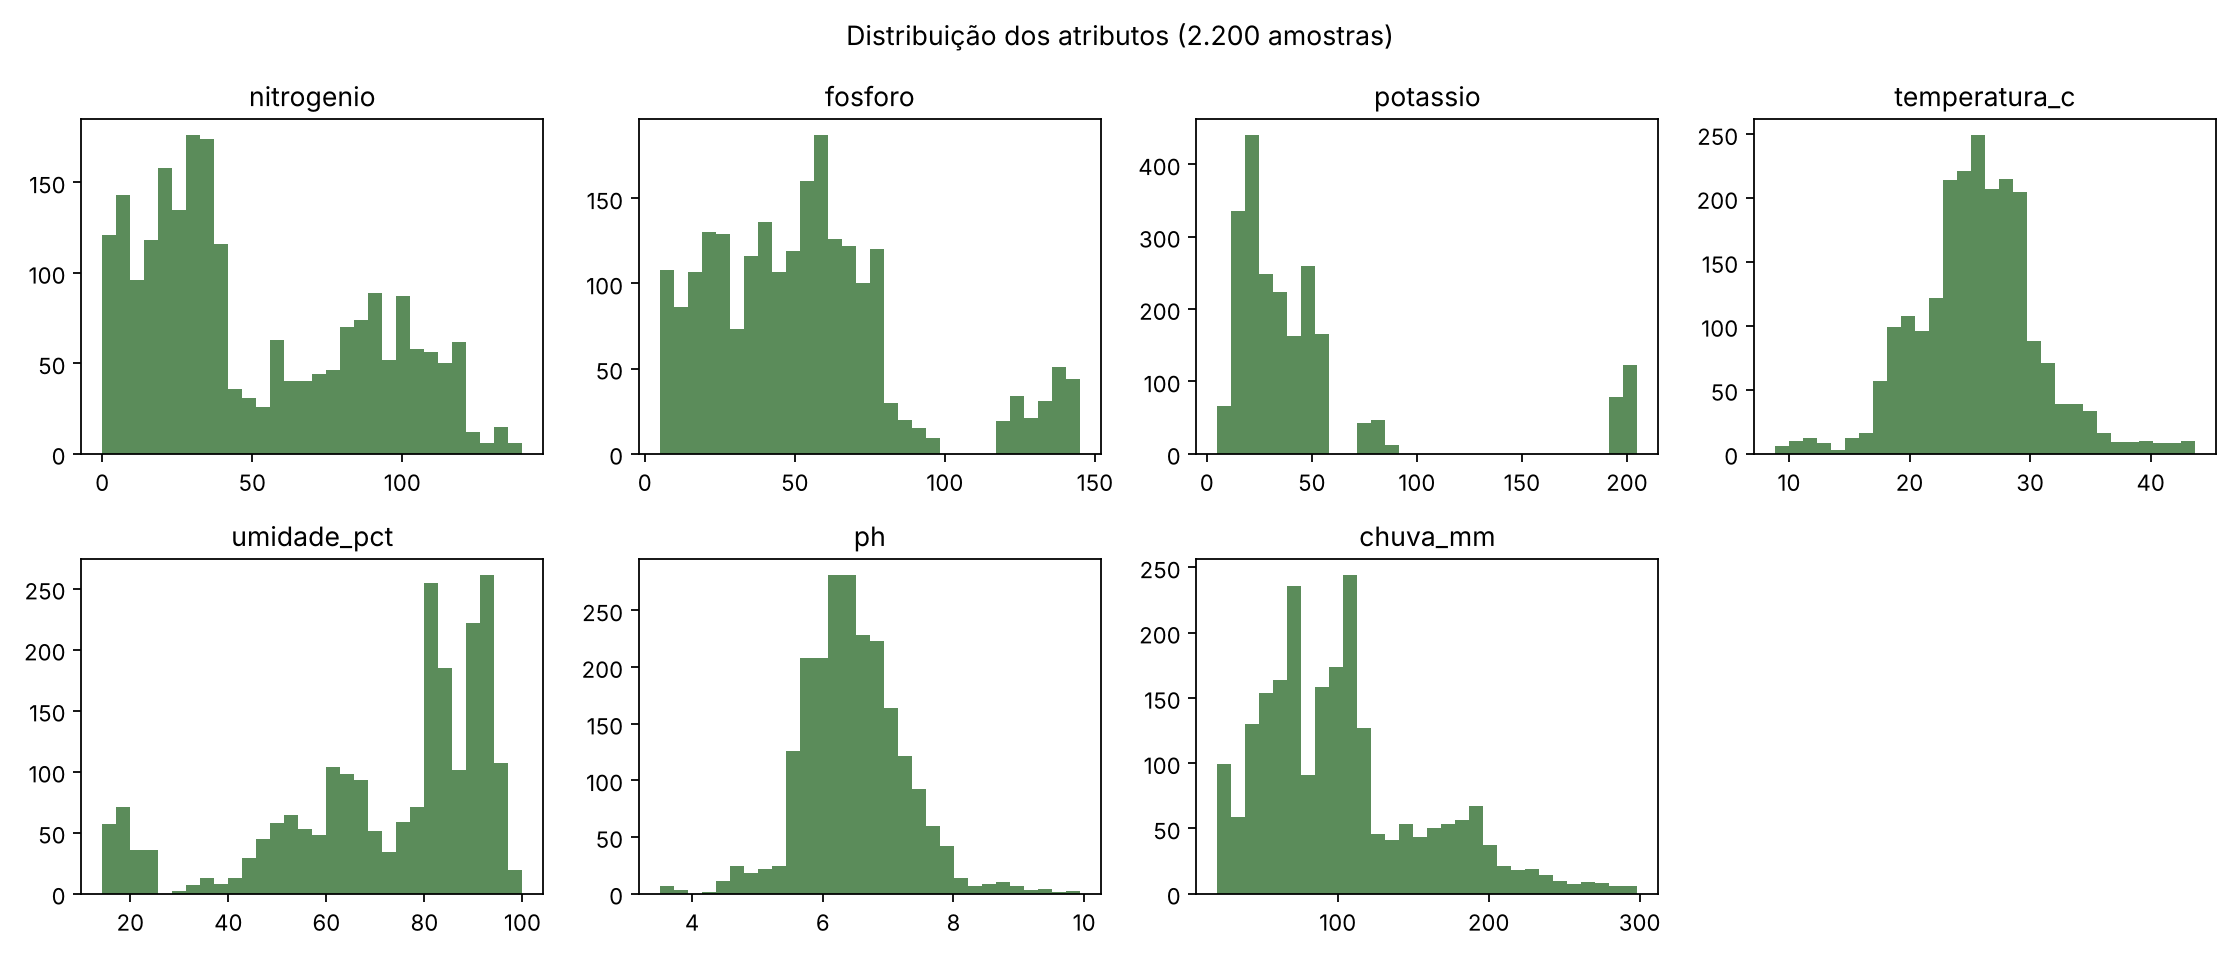

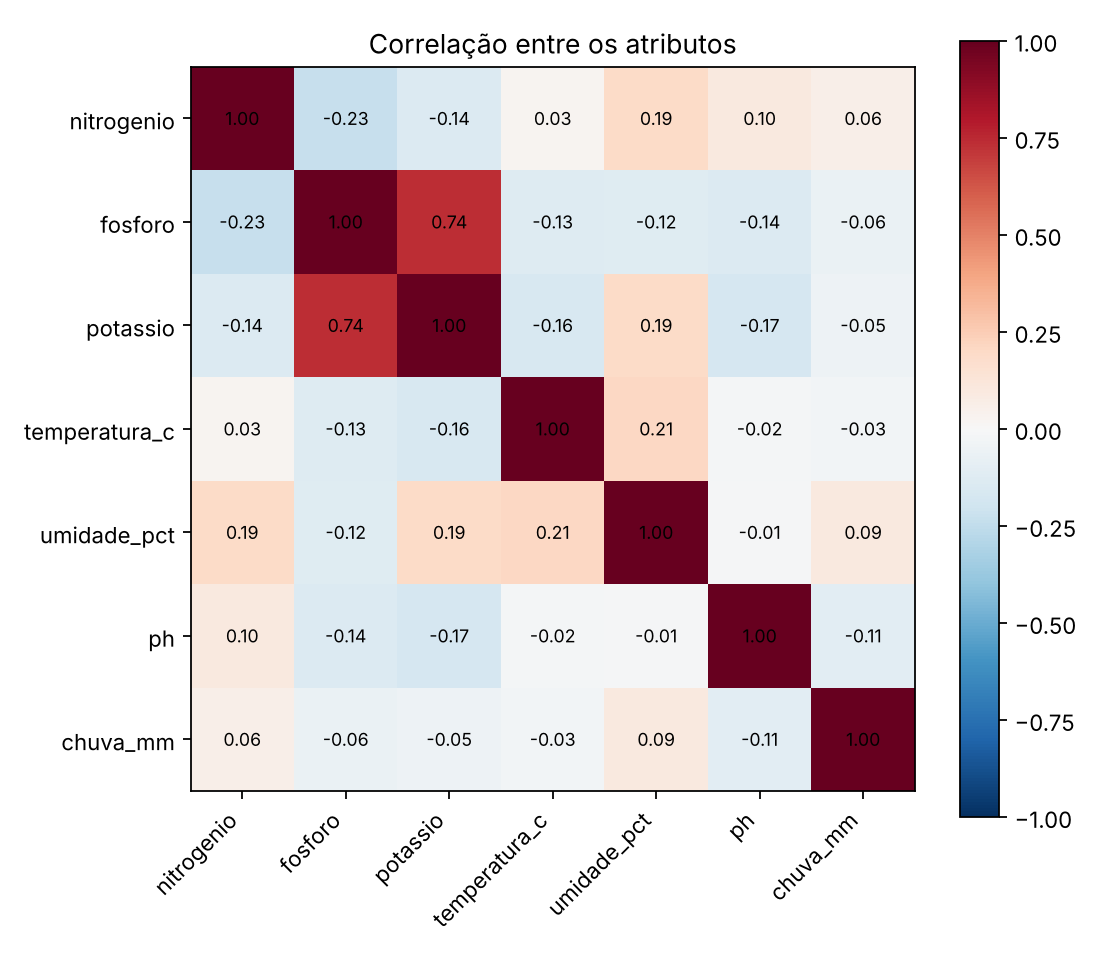

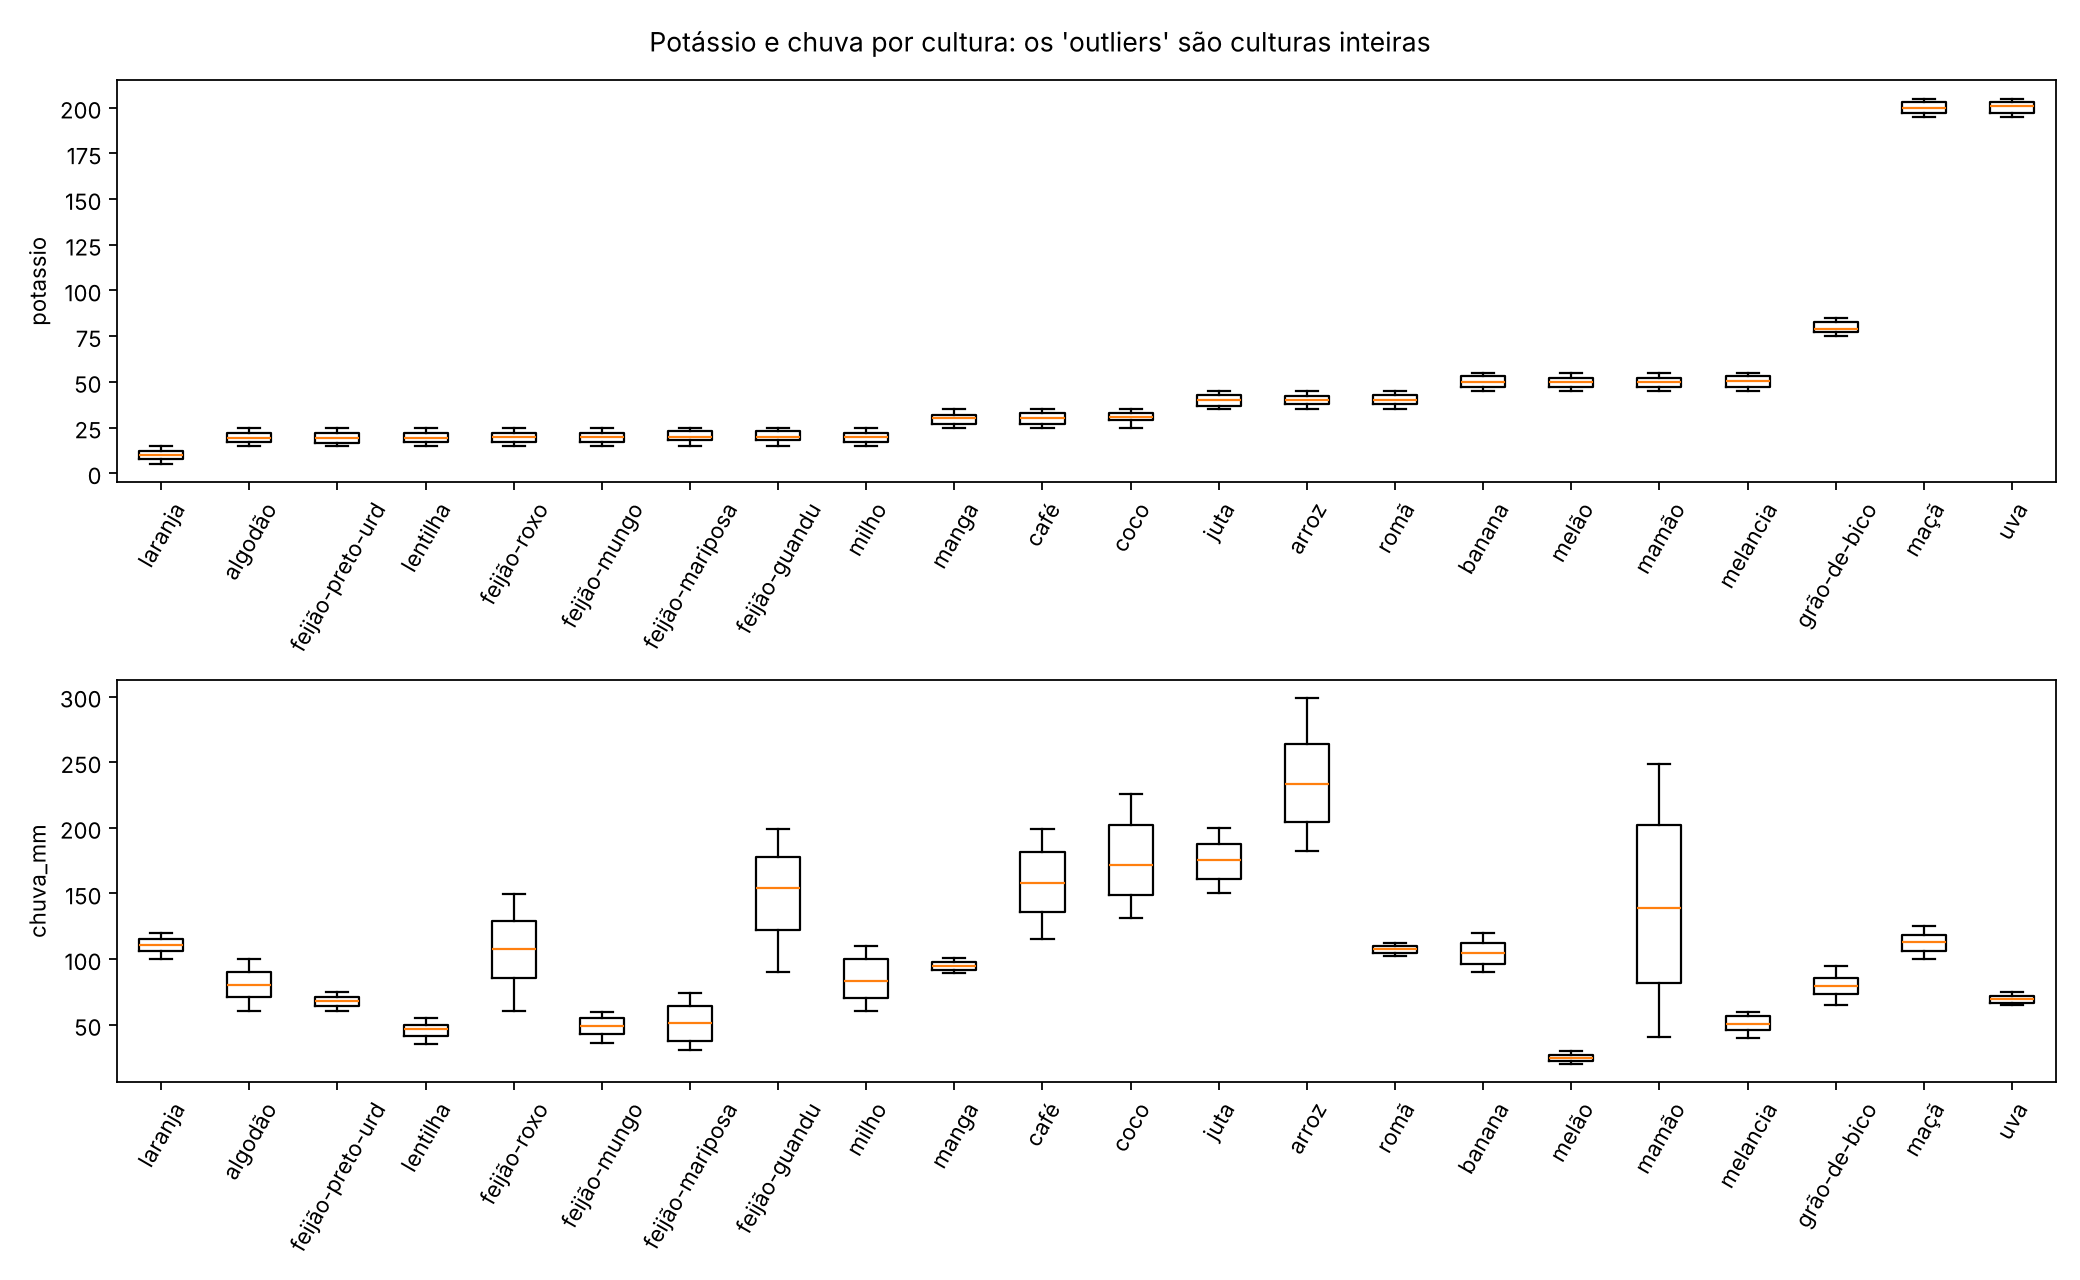

In [7]:
display(Image('resultados/eda_histogramas.png', width=650))
display(Image('resultados/eda_correlacao.png', width=650))
display(Image('resultados/eda_boxplot_culturas.png', width=650))

## 3. Modelos supervisionados: SVM, árvore de decisão e ensembles

Etapas 2 a 4: pré-processamento, treino, otimização e avaliação.

Problema: classificação multiclasse. A partir de N, P, K, temperatura,
umidade, pH e chuva, prever qual das 22 culturas é a mais indicada.
Modelos: SVM (modelo A), árvore de decisão (modelo B) e dois ensembles
(Random Forest e Gradient Boosting).

In [8]:
import time  # Mede o tempo de treino.
import numpy as np  # Operações numéricas.
import pandas as pd  # Tabelas.
import matplotlib  # Gráficos.
import matplotlib.pyplot as plt  # Interface de desenho.
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline  # Encadeia as etapas.
from sklearn.preprocessing import StandardScaler, FunctionTransformer, label_binarize
from sklearn.impute import SimpleImputer  # Tratamento de ausentes.
from sklearn.svm import SVC  # Modelo A.
from sklearn.calibration import CalibratedClassifierCV  # Probabilidades para o SVM.
from sklearn.tree import DecisionTreeClassifier, export_text  # Modelo B.
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.inspection import permutation_importance  # Importância por permutação.
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)
from comum import carregar_dados, criar_atributos, ATRIBUTOS, SAIDA, SEMENTE

In [9]:
# ------------------------------------------------------------------

In [10]:
# 1. Dados e divisão 70% treino, 15% validação, 15% teste
# ------------------------------------------------------------------
dados = carregar_dados()
X = dados[ATRIBUTOS]  # Sete atributos numéricos.
y = dados["cultura"]  # Alvo com 22 classes.

X_tr, X_resto, y_tr, y_resto = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEMENTE)  # 70% para treino.
X_val, X_te, y_val, y_te = train_test_split(
    X_resto, y_resto, test_size=0.50, stratify=y_resto, random_state=SEMENTE)  # 15% + 15%.
print("Treino:", X_tr.shape, "| validação:", X_val.shape, "| teste:", X_te.shape)
# stratify mantém 70, 15 e 15 amostras de cada cultura em cada parte.

Treino: (1540, 7) | validação: (330, 7) | teste: (330, 7)


In [11]:
# ------------------------------------------------------------------

In [12]:
# 2. Pré-processamento dentro do Pipeline
# ------------------------------------------------------------------
# - SimpleImputer(median): o dataset não tem ausentes, mas a etapa protege o
#   sistema contra análises de solo incompletas no uso real.
# - "atributos": passthrough (só os 7 originais) ou criar_atributos (+4 colunas).
#   O GridSearchCV decide se a engenharia de atributos ajuda.
# - StandardScaler: obrigatório no SVM, que usa distâncias. Nas árvores não muda
#   os cortes, mas foi mantido para que todos os modelos recebam a mesma entrada.
engenharia = FunctionTransformer(criar_atributos)  # Acrescenta proporções N:P:K.


def montar(modelo):
    """Cria o Pipeline padrão com o modelo informado na última etapa."""
    return Pipeline([
        ("atributos", "passthrough"),
        ("imputar", SimpleImputer(strategy="median")),
        ("escala", StandardScaler()),
        ("modelo", modelo),
    ])


opcoes_atributos = ["passthrough", engenharia]  # Testadas em todos os modelos.

In [13]:
# ------------------------------------------------------------------

In [14]:
# 3. Modelos e grades de hiperparâmetros
# ------------------------------------------------------------------
buscas = {
    "SVM": (montar(SVC(random_state=SEMENTE)), {
        "atributos": opcoes_atributos,
        "modelo__kernel": ["linear", "rbf"],
        "modelo__C": [0.1, 1, 10, 100],
        "modelo__gamma": ["scale", 0.01, 0.1, 1],
    }),
    "Árvore de decisão": (montar(DecisionTreeClassifier(random_state=SEMENTE)), {
        "atributos": opcoes_atributos,
        "modelo__criterion": ["gini", "entropy"],
        "modelo__max_depth": [4, 6, 8, 10, 12, None],
        "modelo__min_samples_leaf": [1, 2, 4, 8],
        "modelo__ccp_alpha": [0.0, 0.001, 0.005],
    }),
    "Random Forest": (montar(RandomForestClassifier(random_state=SEMENTE, n_jobs=-1)), {
        "atributos": opcoes_atributos,
        "modelo__n_estimators": [100, 300],
        "modelo__max_features": ["sqrt", 0.5],
        "modelo__min_samples_leaf": [1, 3],
    }),
    "Gradient Boosting": (montar(GradientBoostingClassifier(
            n_estimators=150, subsample=0.8, random_state=SEMENTE)), {
        "atributos": opcoes_atributos,
        "modelo__learning_rate": [0.05, 0.1],
        "modelo__max_depth": [2, 3],
    }),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)  # 5 rodadas.
finais = {}  # Melhor pipeline de cada família.
linhas_val = []  # Resultados na validação.
for nome, (pipe, grade) in buscas.items():
    inicio = time.time()
    busca = GridSearchCV(pipe, grade, cv=cv, scoring="f1_macro", n_jobs=-1)
    busca.fit(X_tr, y_tr)  # Só o treino participa da escolha.
    segundos = time.time() - inicio
    finais[nome] = busca.best_estimator_  # Já reajustado com todo o treino.
    prev_val = busca.predict(X_val)  # Validação: compara famílias de modelos.
    usa_eng = busca.best_params_["atributos"] != "passthrough"
    params = {k.replace("modelo__", ""): v for k, v in busca.best_params_.items()
              if k != "atributos"}
    print(f"\n{nome}: melhores parâmetros {params} | engenharia de atributos: {usa_eng}")
    print(f"  F1 macro CV = {busca.best_score_:.4f} | F1 macro validação = "
          f"{f1_score(y_val, prev_val, average='macro'):.4f} | tempo da busca = {segundos:.0f} s")
    # Efeito isolado da engenharia de atributos: melhor resultado de CV com e sem ela.
    res = pd.DataFrame(busca.cv_results_)
    com = res[res.param_atributos.astype(str) != "passthrough"].mean_test_score.max()
    sem = res[res.param_atributos.astype(str) == "passthrough"].mean_test_score.max()
    print(f"  Melhor F1 CV sem novos atributos = {sem:.4f} | com novos atributos = {com:.4f}")
    linhas_val.append({"modelo": nome, "parametros": str(params),
                       "engenharia_atributos": usa_eng,
                       "f1_cv": busca.best_score_, "f1_cv_sem_eng": sem, "f1_cv_com_eng": com,
                       "f1_validacao": f1_score(y_val, prev_val, average="macro"),
                       "tempo_busca_s": segundos})
pd.DataFrame(linhas_val).round(4).to_csv(SAIDA / "modelos_validacao.csv", index=False)

# O SVC não devolve probabilidades. Para a curva ROC, calibramos o pipeline
# escolhido com validação cruzada interna (só no treino). As classes previstas
# continuam vindo do SVC original.
probabilistico = {nome: modelo for nome, modelo in finais.items()}
probabilistico["SVM"] = CalibratedClassifierCV(finais["SVM"], cv=5, ensemble=False).fit(X_tr, y_tr)


SVM: melhores parâmetros {'C': 100, 'gamma': 0.01, 'kernel': 'rbf'} | engenharia de atributos: True
  F1 macro CV = 0.9876 | F1 macro validação = 0.9909 | tempo da busca = 4 s
  Melhor F1 CV sem novos atributos = 0.9869 | com novos atributos = 0.9876



Árvore de decisão: melhores parâmetros {'ccp_alpha': 0.0, 'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 1} | engenharia de atributos: False
  F1 macro CV = 0.9883 | F1 macro validação = 0.9909 | tempo da busca = 6 s
  Melhor F1 CV sem novos atributos = 0.9883 | com novos atributos = 0.9824



Random Forest: melhores parâmetros {'max_features': 'sqrt', 'min_samples_leaf': 3, 'n_estimators': 100} | engenharia de atributos: False
  F1 macro CV = 0.9948 | F1 macro validação = 0.9970 | tempo da busca = 12 s
  Melhor F1 CV sem novos atributos = 0.9948 | com novos atributos = 0.9941



Gradient Boosting: melhores parâmetros {'learning_rate': 0.1, 'max_depth': 3} | engenharia de atributos: False
  F1 macro CV = 0.9851 | F1 macro validação = 0.9909 | tempo da busca = 64 s
  Melhor F1 CV sem novos atributos = 0.9851 | com novos atributos = 0.9811


In [15]:
# ------------------------------------------------------------------

In [16]:
# 4. Avaliação final no teste (usado uma única vez)
# ------------------------------------------------------------------
classes = finais["SVM"].classes_  # Ordem alfabética das culturas.
y_te_bin = label_binarize(y_te, classes=classes)  # Uma coluna 0/1 por cultura.
linhas = []
for nome, modelo in finais.items():
    prev = modelo.predict(X_te)
    prob = probabilistico[nome].predict_proba(X_te)  # Probabilidade de cada cultura.
    linhas.append({
        "modelo": nome,
        "accuracy": accuracy_score(y_te, prev),
        "precision_macro": precision_score(y_te, prev, average="macro"),
        "recall_macro": recall_score(y_te, prev, average="macro"),
        "f1_macro": f1_score(y_te, prev, average="macro"),
        "roc_auc_macro_ovr": roc_auc_score(y_te, prob, multi_class="ovr", average="macro"),
        "erros": int((prev != y_te).sum()),
    })
    print(f"\n=== {nome}: relatório no teste ===")
    print(classification_report(y_te, prev, digits=3, zero_division=0))
    erros = pd.DataFrame({"real": y_te, "previsto": prev})[prev != y_te]
    print("Erros (real -> previsto):", list(zip(erros.real, erros.previsto)))

    fig, ax = plt.subplots(figsize=(10, 9))
    ConfusionMatrixDisplay(confusion_matrix(y_te, prev, labels=classes),
                           display_labels=classes).plot(ax=ax, cmap="Greens",
                                                        colorbar=False, xticks_rotation=90)
    ax.set_title(f"{nome}: matriz de confusão no teste (330 amostras)")
    fig.tight_layout()
    arquivo = nome.split()[0].lower().replace("á", "a")
    fig.savefig(SAIDA / f"matriz_confusao_{arquivo}.png", dpi=150)
    plt.close(fig)

metricas = pd.DataFrame(linhas)
print("\nComparação no teste:\n", metricas.round(4).to_string(index=False))
metricas.round(4).to_csv(SAIDA / "modelos_teste.csv", index=False)

# Curva ROC média (micro, um contra o resto) de cada modelo.
fig, ax = plt.subplots(figsize=(6, 5))
for nome in finais:
    prob = probabilistico[nome].predict_proba(X_te)
    fpr, tpr, _ = roc_curve(y_te_bin.ravel(), prob.ravel())  # Junta as 22 classes.
    auc = roc_auc_score(y_te_bin, prob, average="micro")
    ax.plot(fpr, tpr, label=f"{nome} (AUC micro = {auc:.4f})")
ax.plot([1e-4, 1], [1e-4, 1], "k--", linewidth=1)  # Classificador aleatório.
ax.set_xscale("log")  # Escala log para enxergar a região de poucos falsos positivos.
ax.set_xlim(1e-4, 1)
ax.set_xlabel("Taxa de falsos positivos (escala log)")
ax.set_ylabel("Taxa de verdadeiros positivos")
ax.set_title("Curvas ROC no teste (média micro, um contra o resto)")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(SAIDA / "curvas_roc.png", dpi=160)
plt.close(fig)


=== SVM: relatório no teste ===
                  precision    recall  f1-score   support

         algodão      0.938     1.000     0.968        15
           arroz      1.000     0.867     0.929        15
          banana      1.000     1.000     1.000        15
            café      1.000     1.000     1.000        15
            coco      1.000     1.000     1.000        15
   feijão-guandu      1.000     1.000     1.000        15
 feijão-mariposa      1.000     1.000     1.000        15
    feijão-mungo      1.000     1.000     1.000        15
feijão-preto-urd      1.000     0.933     0.966        15
     feijão-roxo      1.000     1.000     1.000        15
    grão-de-bico      1.000     1.000     1.000        15
            juta      0.882     1.000     0.938        15
         laranja      1.000     1.000     1.000        15
        lentilha      0.938     1.000     0.968        15
           mamão      1.000     1.000     1.000        15
           manga      1.000     1.000 


=== Árvore de decisão: relatório no teste ===
                  precision    recall  f1-score   support

         algodão      1.000     1.000     1.000        15
           arroz      1.000     1.000     1.000        15
          banana      1.000     1.000     1.000        15
            café      1.000     1.000     1.000        15
            coco      1.000     1.000     1.000        15
   feijão-guandu      1.000     1.000     1.000        15
 feijão-mariposa      1.000     1.000     1.000        15
    feijão-mungo      1.000     1.000     1.000        15
feijão-preto-urd      1.000     1.000     1.000        15
     feijão-roxo      1.000     1.000     1.000        15
    grão-de-bico      1.000     1.000     1.000        15
            juta      1.000     1.000     1.000        15
         laranja      1.000     1.000     1.000        15
        lentilha      1.000     1.000     1.000        15
           mamão      1.000     1.000     1.000        15
           manga      1.


=== Random Forest: relatório no teste ===
                  precision    recall  f1-score   support

         algodão      1.000     1.000     1.000        15
           arroz      1.000     0.933     0.966        15
          banana      1.000     1.000     1.000        15
            café      1.000     1.000     1.000        15
            coco      1.000     1.000     1.000        15
   feijão-guandu      1.000     1.000     1.000        15
 feijão-mariposa      1.000     1.000     1.000        15
    feijão-mungo      1.000     1.000     1.000        15
feijão-preto-urd      1.000     1.000     1.000        15
     feijão-roxo      1.000     1.000     1.000        15
    grão-de-bico      1.000     1.000     1.000        15
            juta      0.938     1.000     0.968        15
         laranja      1.000     1.000     1.000        15
        lentilha      1.000     1.000     1.000        15
           mamão      1.000     1.000     1.000        15
           manga      1.000 


=== Gradient Boosting: relatório no teste ===
                  precision    recall  f1-score   support

         algodão      1.000     1.000     1.000        15
           arroz      1.000     0.933     0.966        15
          banana      1.000     1.000     1.000        15
            café      1.000     1.000     1.000        15
            coco      1.000     1.000     1.000        15
   feijão-guandu      1.000     1.000     1.000        15
 feijão-mariposa      1.000     1.000     1.000        15
    feijão-mungo      1.000     1.000     1.000        15
feijão-preto-urd      1.000     1.000     1.000        15
     feijão-roxo      1.000     1.000     1.000        15
    grão-de-bico      1.000     1.000     1.000        15
            juta      0.882     1.000     0.938        15
         laranja      1.000     1.000     1.000        15
        lentilha      1.000     1.000     1.000        15
           mamão      1.000     0.933     0.966        15
           manga      1.


Comparação no teste:
            modelo  accuracy  precision_macro  recall_macro  f1_macro  roc_auc_macro_ovr  erros
              SVM    0.9879           0.9890        0.9879    0.9878             0.9995      4
Árvore de decisão    1.0000           1.0000        1.0000    1.0000             1.0000      0
    Random Forest    0.9970           0.9972        0.9970    0.9970             1.0000      1
Gradient Boosting    0.9939           0.9947        0.9939    0.9940             1.0000      2


In [17]:
# ------------------------------------------------------------------

In [18]:
# 5. Importância dos atributos
# ------------------------------------------------------------------
nomes_entrada = {}  # Nomes das colunas que chegam ao modelo (7 ou 11).
for nome, modelo in finais.items():
    passo = modelo.named_steps["atributos"]
    nomes_entrada[nome] = (list(criar_atributos(X_tr.head(1)).columns)
                           if passo != "passthrough" else ATRIBUTOS)

imp_tabelas = {}
for nome in ["Árvore de decisão", "Random Forest", "Gradient Boosting"]:
    m = finais[nome].named_steps["modelo"]
    imp_tabelas[nome] = pd.Series(m.feature_importances_, index=nomes_entrada[nome])
imp = pd.DataFrame(imp_tabelas).fillna(0).sort_values("Random Forest", ascending=False)
print("\nImportância por impureza (soma 1 em cada modelo):\n", imp.round(3))
imp.round(4).to_csv(SAIDA / "importancia_impureza.csv")

# Permutação no teste: vale para qualquer modelo, inclusive o SVM.
perm = {}
for nome, modelo in finais.items():
    r = permutation_importance(modelo, X_te, y_te, scoring="f1_macro",
                               n_repeats=20, random_state=SEMENTE, n_jobs=-1)
    perm[nome] = pd.Series(r.importances_mean, index=ATRIBUTOS)
perm = pd.DataFrame(perm).sort_values("Random Forest", ascending=False)
print("\nQueda do F1 macro ao embaralhar cada atributo original:\n", perm.round(3))
perm.round(4).to_csv(SAIDA / "importancia_permutacao.csv")

fig, ax = plt.subplots(figsize=(8, 4.5))
perm.iloc[::-1].plot.barh(ax=ax, width=0.8)
ax.set_xlabel("Queda do F1 macro no teste ao embaralhar o atributo")
ax.set_title("Importância por permutação")
fig.tight_layout()
fig.savefig(SAIDA / "importancia_permutacao.png", dpi=160)
plt.close(fig)

# Regras do topo da árvore (3 primeiros níveis), em unidades padronizadas.
arvore = finais["Árvore de decisão"].named_steps["modelo"]
print("\nÁrvore final | profundidade:", arvore.get_depth(), "| folhas:", arvore.get_n_leaves())
print(export_text(arvore, feature_names=nomes_entrada["Árvore de decisão"], max_depth=3))

# Árvore sem escala só para ler os cortes nas unidades originais.
leitura = DecisionTreeClassifier(**{k: v for k, v in arvore.get_params().items()})
leitura.fit(criar_atributos(X_tr) if nomes_entrada["Árvore de decisão"] != ATRIBUTOS else X_tr, y_tr)
print("Regras nas unidades originais (3 níveis):")
print(export_text(leitura, feature_names=nomes_entrada["Árvore de decisão"], max_depth=3, decimals=1))


Importância por impureza (soma 1 em cada modelo):
                Árvore de decisão  Random Forest  Gradient Boosting
chuva_mm                   0.270          0.229              0.226
umidade_pct                0.225          0.217              0.238
potassio                   0.094          0.171              0.166
fosforo                    0.209          0.153              0.145
nitrogenio                 0.141          0.111              0.120
temperatura_c              0.053          0.067              0.062
ph                         0.008          0.051              0.044



Queda do F1 macro ao embaralhar cada atributo original:
                  SVM  Árvore de decisão  Random Forest  Gradient Boosting
umidade_pct    0.352              0.521          0.312              0.387
nitrogenio     0.347              0.225          0.214              0.201
chuva_mm       0.355              0.334          0.190              0.398
potassio       0.378              0.368          0.152              0.151
fosforo        0.252              0.450          0.132              0.228
ph             0.033              0.019          0.013              0.015
temperatura_c  0.057              0.064          0.001              0.013



Árvore final | profundidade: 15 | folhas: 38
|--- chuva_mm <= -1.33
|   |--- class: melão
|--- chuva_mm >  -1.33
|   |--- umidade_pct <= -1.96
|   |   |--- potassio <= 0.04
|   |   |   |--- class: feijão-roxo
|   |   |--- potassio >  0.04
|   |   |   |--- class: grão-de-bico
|   |--- umidade_pct >  -1.96
|   |   |--- fosforo <= 1.64
|   |   |   |--- potassio <= -0.45
|   |   |   |   |--- truncated branch of depth 8
|   |   |   |--- potassio >  -0.45
|   |   |   |   |--- truncated branch of depth 12
|   |   |--- fosforo >  1.64
|   |   |   |--- chuva_mm <= -0.29
|   |   |   |   |--- class: uva
|   |   |   |--- chuva_mm >  -0.29
|   |   |   |   |--- class: maçã

Regras nas unidades originais (3 níveis):
|--- chuva_mm <= 30.8
|   |--- class: melão
|--- chuva_mm >  30.8
|   |--- umidade_pct <= 27.7
|   |   |--- potassio <= 50.0
|   |   |   |--- class: feijão-roxo
|   |   |--- potassio >  50.0
|   |   |   |--- class: grão-de-bico
|   |--- umidade_pct >  27.7
|   |   |--- fosforo <= 107.5
|

In [19]:
# ------------------------------------------------------------------

In [20]:
# 6. Uso prático: recomendação para uma análise de solo nova
# ------------------------------------------------------------------
# O modelo final é escolhido pela validação, não pelo teste.
validacao = pd.DataFrame(linhas_val)
melhor = validacao.sort_values("f1_validacao", ascending=False, kind="stable").iloc[0].modelo
nova = pd.DataFrame([{"nitrogenio": 80, "fosforo": 45, "potassio": 40, "temperatura_c": 24.0,
                      "umidade_pct": 82.0, "ph": 6.3, "chuva_mm": 220.0}])
prob = pd.Series(probabilistico[melhor].predict_proba(nova)[0], index=classes).sort_values(ascending=False)
print(f"\nModelo usado: {melhor}. Três culturas mais prováveis para a área nova:")
print(prob.head(3).round(3))


Modelo usado: Random Forest. Três culturas mais prováveis para a área nova:
arroz    0.913
juta     0.082
mamão    0.005
dtype: float64


In [21]:
# ------------------------------------------------------------------

In [22]:
# 7. Robustez: validação cruzada repetida (treino + validação, sem o teste)
# ------------------------------------------------------------------
# O teste tem 15 amostras por cultura; 1 erro muda a acurácia em 0,3 ponto.
# Repetir a validação cruzada mostra se as diferenças entre modelos são reais.
from sklearn.base import clone  # Cópia do pipeline sem o ajuste.
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
X_dev = pd.concat([X_tr, X_val])  # 1870 amostras (85%).
y_dev = pd.concat([y_tr, y_val])
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=SEMENTE)  # 20 rodadas.
robustez = []
for nome, modelo in finais.items():
    notas = cross_val_score(clone(modelo), X_dev, y_dev, cv=rcv, scoring="f1_macro", n_jobs=-1)
    robustez.append({"modelo": nome, "f1_medio": notas.mean(), "desvio": notas.std(),
                     "minimo": notas.min(), "maximo": notas.max()})
robustez = pd.DataFrame(robustez)
print("\nValidação cruzada repetida (5 x 4 = 20 rodadas, F1 macro):\n",
      robustez.round(4).to_string(index=False))
robustez.round(4).to_csv(SAIDA / "modelos_cv_repetida.csv", index=False)


Validação cruzada repetida (5 x 4 = 20 rodadas, F1 macro):
            modelo  f1_medio  desvio  minimo  maximo
              SVM    0.9870  0.0065  0.9758  0.9973
Árvore de decisão    0.9855  0.0062  0.9754  0.9973
    Random Forest    0.9936  0.0033  0.9866  1.0000
Gradient Boosting    0.9834  0.0063  0.9729  0.9947


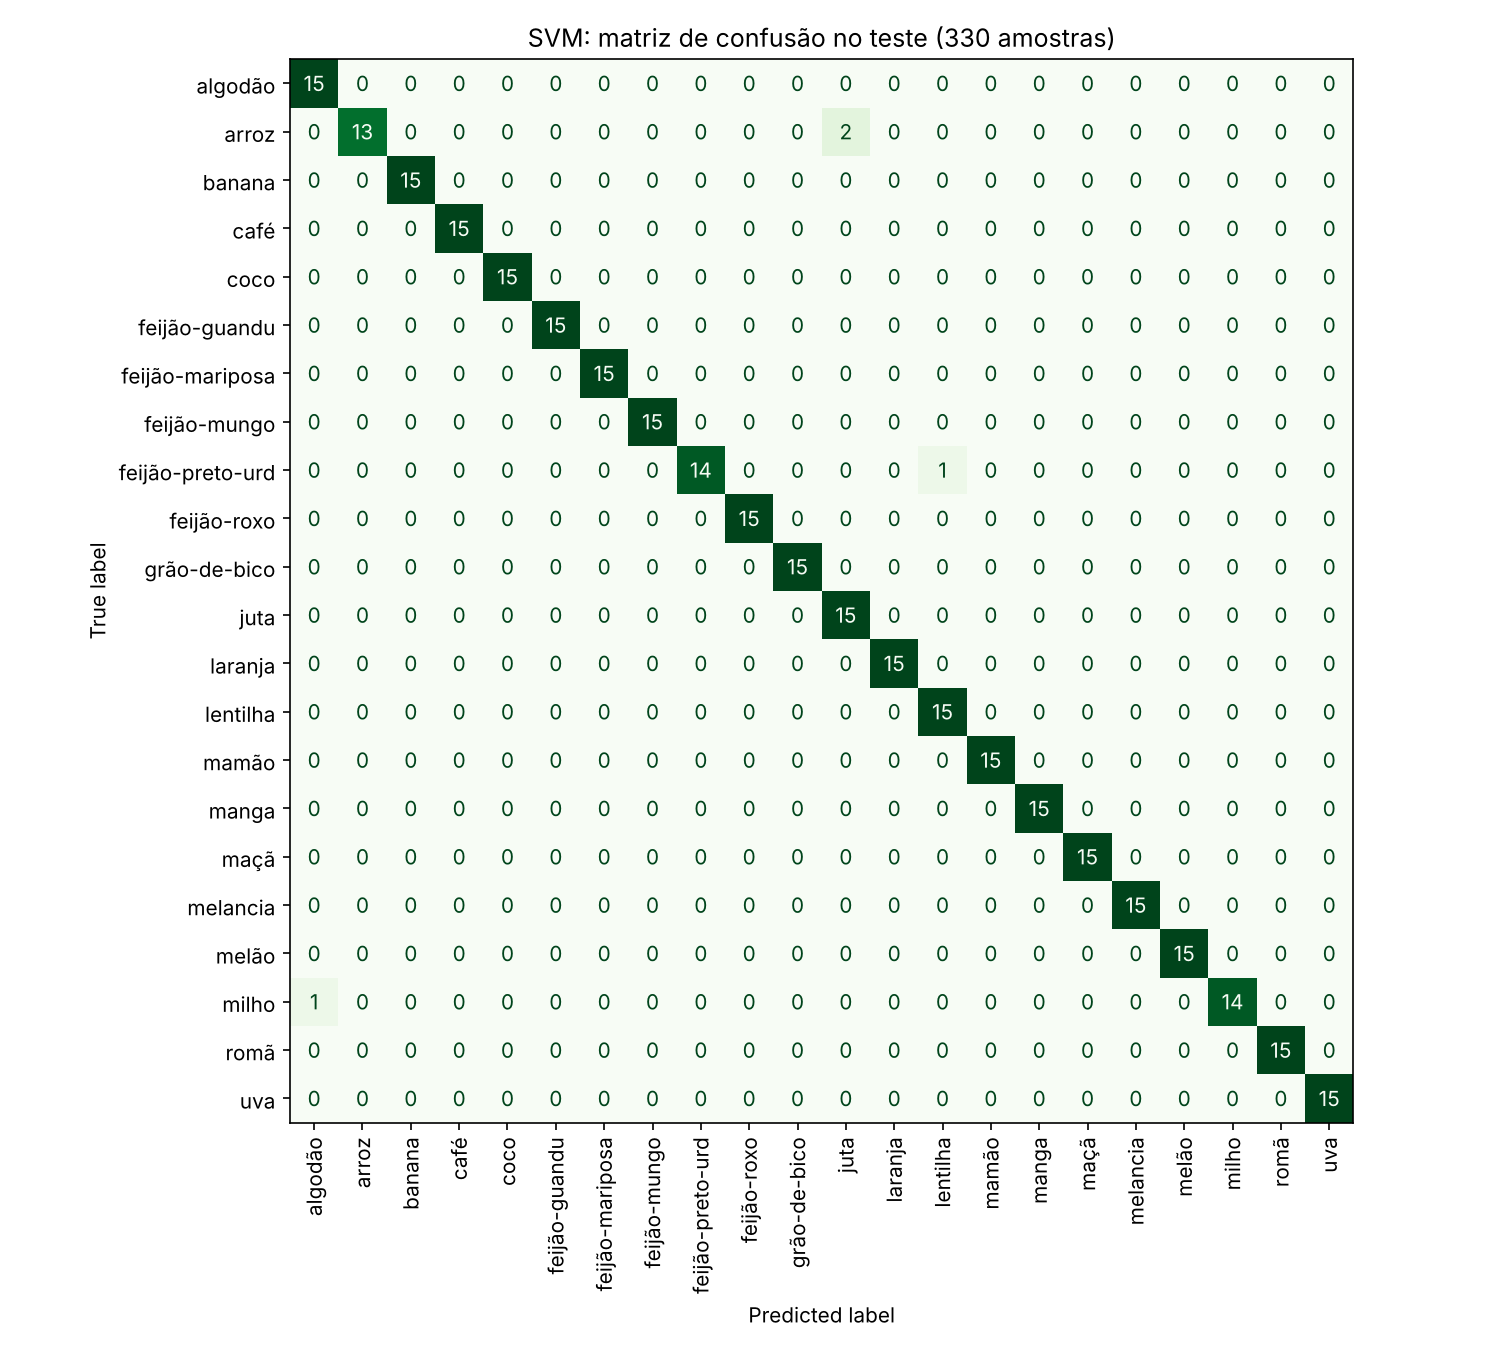

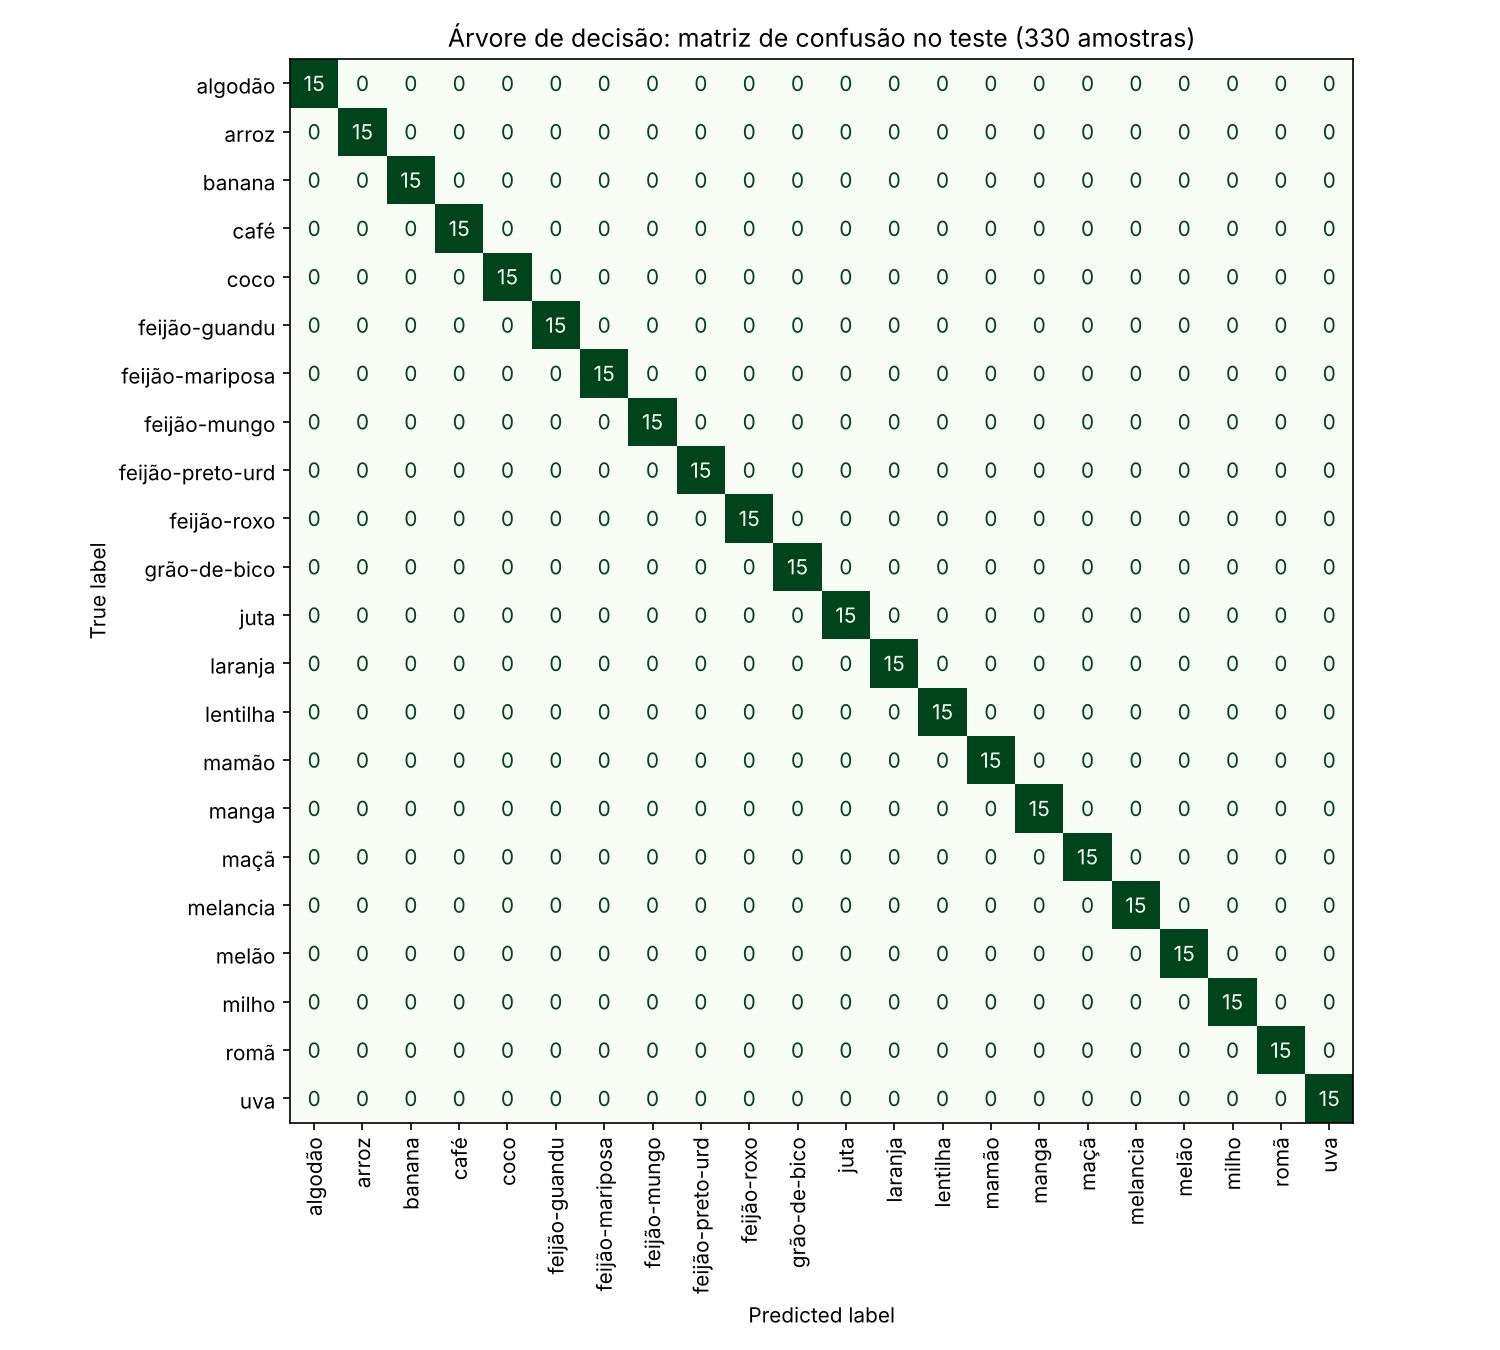

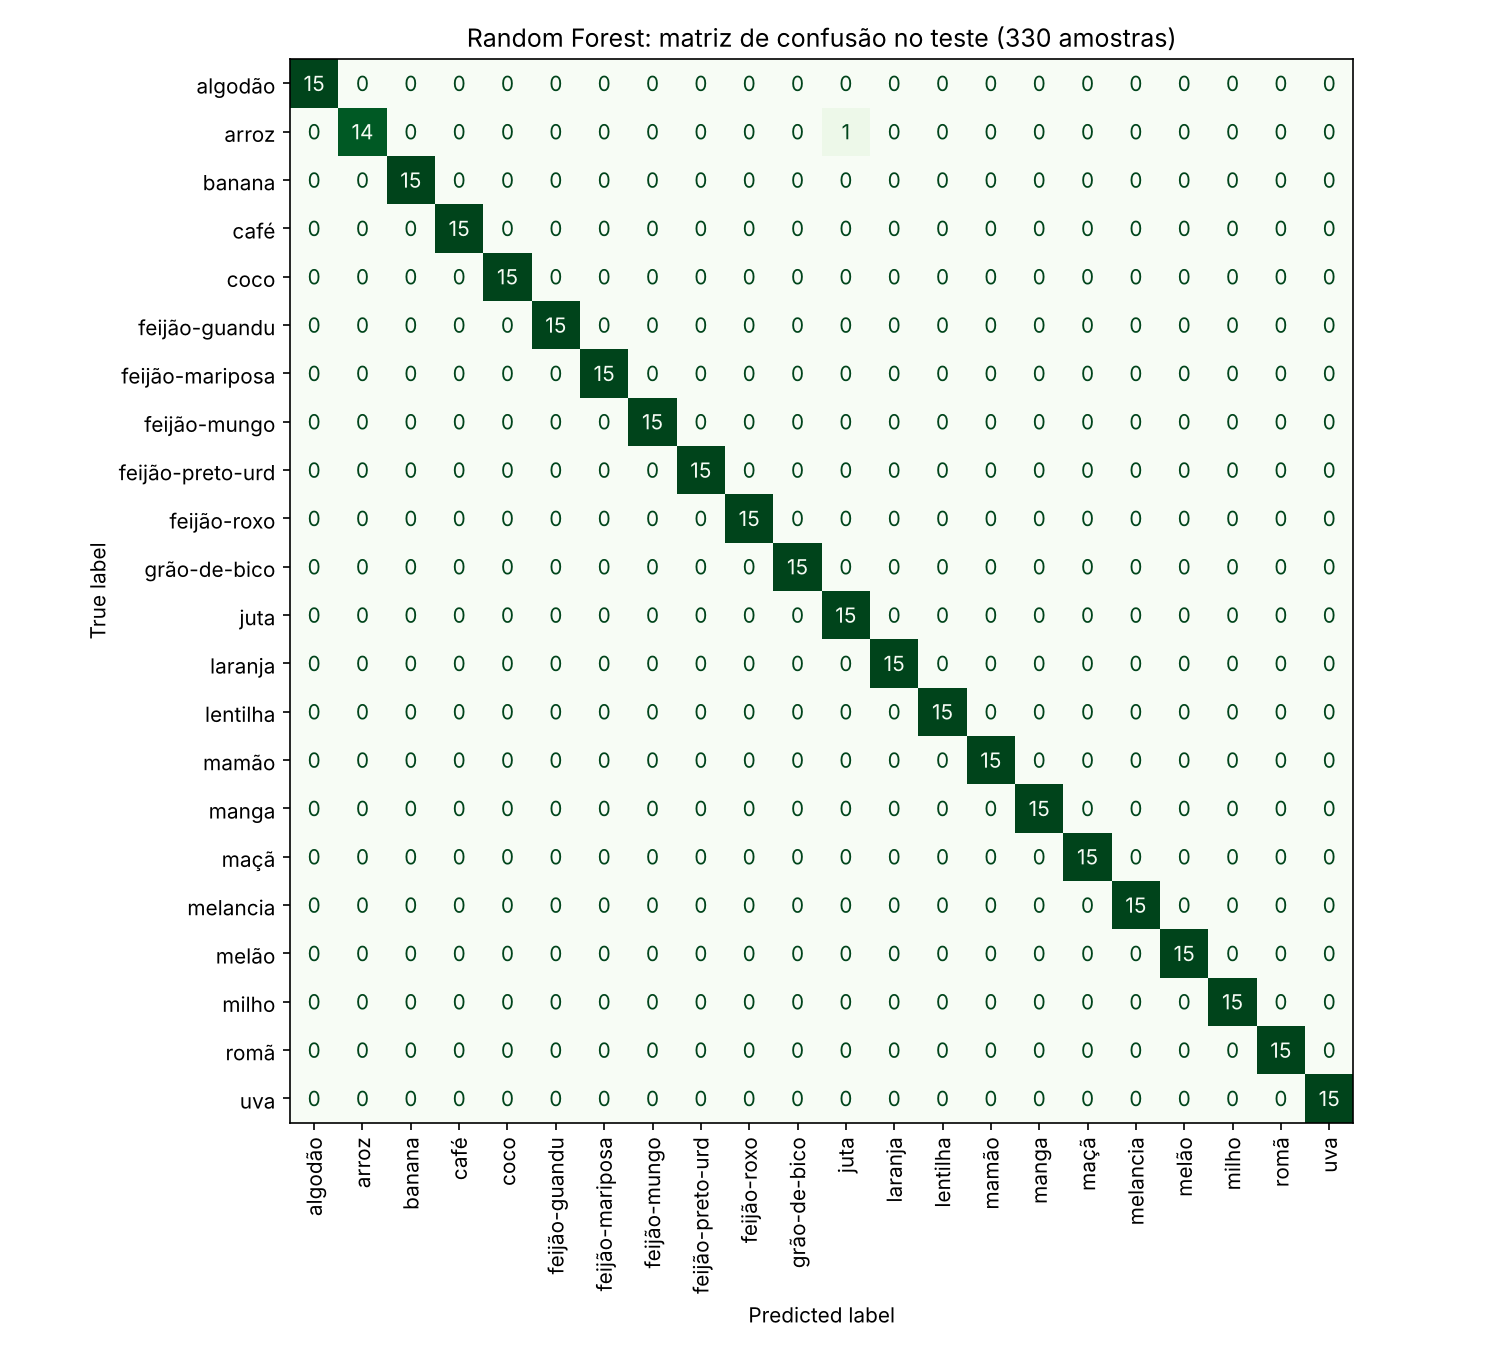

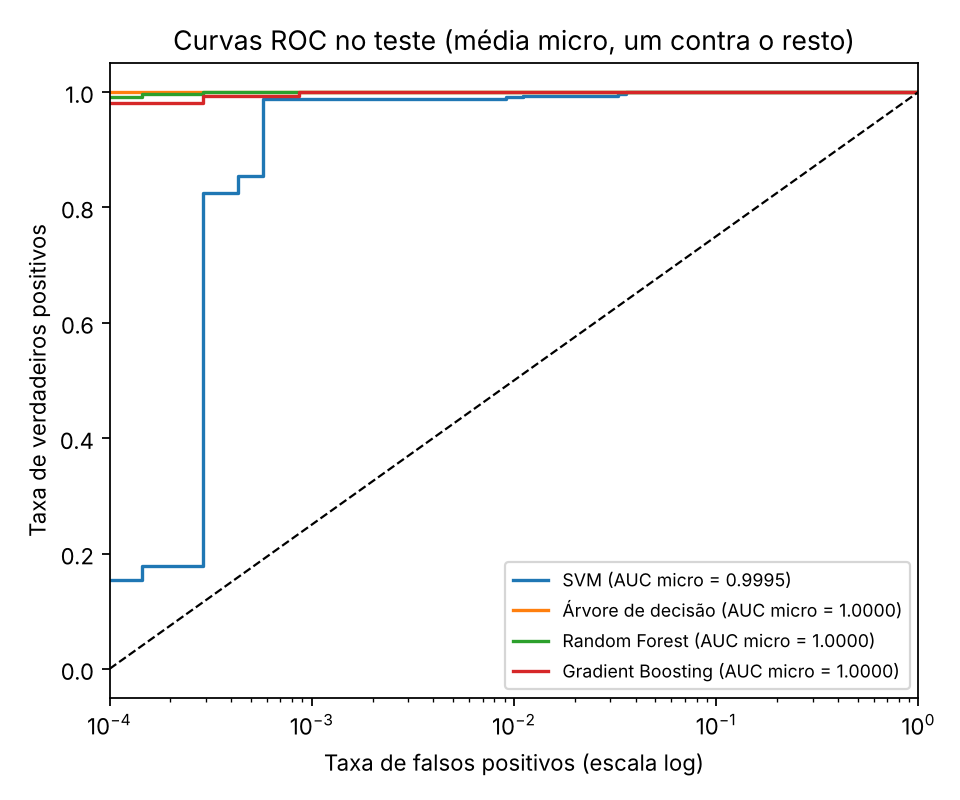

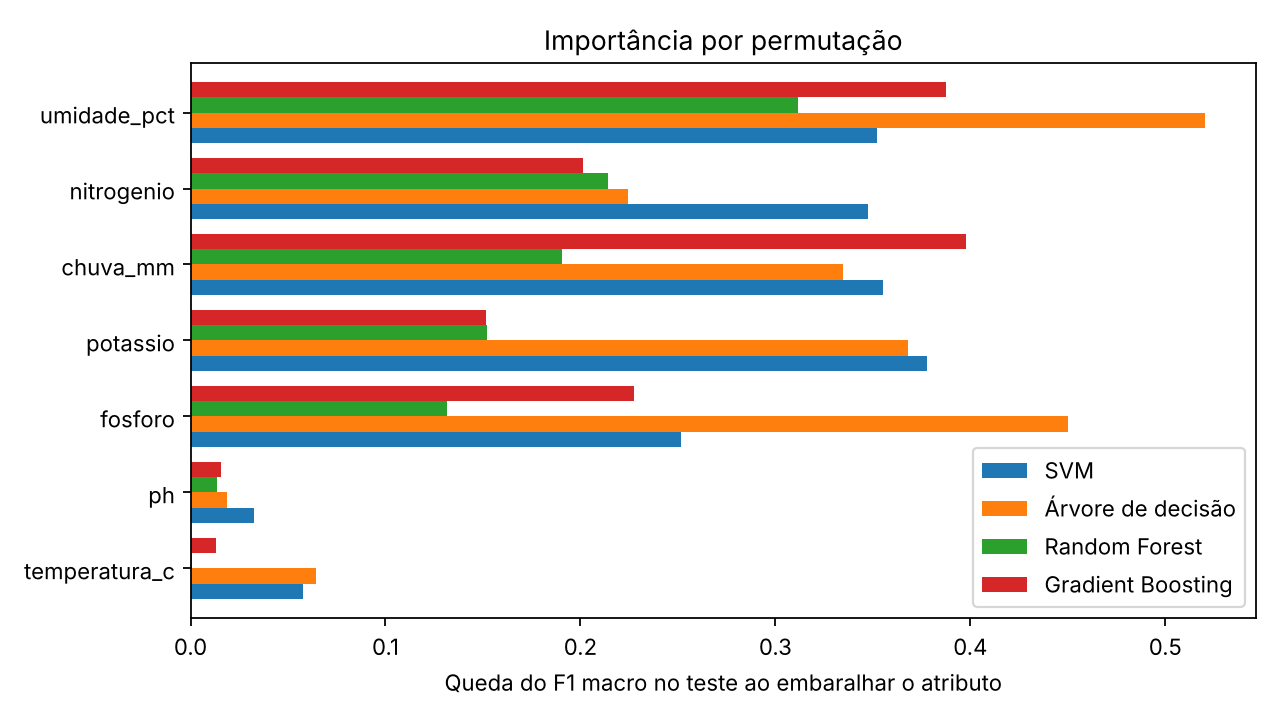

In [23]:
display(Image('resultados/matriz_confusao_svm.png', width=650))
display(Image('resultados/matriz_confusao_arvore.png', width=650))
display(Image('resultados/matriz_confusao_random.png', width=650))
display(Image('resultados/curvas_roc.png', width=650))
display(Image('resultados/importancia_permutacao.png', width=650))

## 4. Modelo não supervisionado: K-means

Etapa 5 (não supervisionada): perfis de ambiente de cultivo com K-means.

Pergunta: sem olhar a cultura, as 2.200 amostras de solo e clima formam
grupos de condições parecidas? Quais culturas caem em cada grupo?
O resultado ajuda a encontrar culturas que podem substituir umas às outras
em uma mesma condição de ambiente.

In [24]:
import numpy as np  # Operações numéricas.
import pandas as pd  # Tabelas.
import matplotlib  # Gráficos.
import matplotlib.pyplot as plt  # Interface de desenho.
from sklearn.pipeline import Pipeline  # Sequência de preparação.
from sklearn.impute import SimpleImputer  # Ausentes (por segurança).
from sklearn.preprocessing import StandardScaler  # Mesma escala para todas as colunas.
from sklearn.cluster import KMeans  # Agrupamento.
from sklearn.decomposition import PCA  # Projeção em 2 dimensões para o gráfico.
from sklearn.metrics import silhouette_score, adjusted_rand_score
from comum import carregar_dados, ATRIBUTOS, SAIDA, SEMENTE

dados = carregar_dados()
X = dados[ATRIBUTOS]  # A cultura NÃO entra no agrupamento.
preparacao = Pipeline([("imputar", SimpleImputer(strategy="median")),
                       ("escala", StandardScaler())])  # K-means usa distância euclidiana.
Z = preparacao.fit_transform(X)  # Matriz 2200 x 7 padronizada.

In [25]:
# 1. Comparação de K = 2 a 15
avaliacoes, modelos = [], {}
for k in range(2, 16):
    km = KMeans(n_clusters=k, init="k-means++", n_init=20, random_state=SEMENTE)
    rot = km.fit_predict(Z)  # Grupo de cada amostra.
    avaliacoes.append([k, km.inertia_, silhouette_score(Z, rot)])
    modelos[k] = km
avaliacao = pd.DataFrame(avaliacoes, columns=["k", "inercia", "silhueta"])
print(avaliacao.round(3).to_string(index=False))
avaliacao.round(3).to_csv(SAIDA / "kmeans_escolha_k.csv", index=False)

fig, eixos = plt.subplots(1, 2, figsize=(11, 4))
eixos[0].plot(avaliacao.k, avaliacao.inercia, "o-")
eixos[0].set_xlabel("Número de grupos K"); eixos[0].set_ylabel("Inércia")
eixos[1].plot(avaliacao.k, avaliacao.silhueta, "o-")
eixos[1].axvline(7, color="gray", linestyle="--")  # K escolhido.
eixos[1].set_xlabel("Número de grupos K"); eixos[1].set_ylabel("Silhueta média")
fig.tight_layout()
fig.savefig(SAIDA / "kmeans_escolha_k.png", dpi=160)
plt.close(fig)

 k   inercia  silhueta
 2 11738.011     0.417
 3  9489.462     0.252
 4  8105.864     0.255
 5  6856.212     0.292
 6  6045.093     0.304
 7  5248.626     0.333
 8  4842.083     0.327
 9  4472.455     0.332
10  4110.154     0.349
11  3845.097     0.347
12  3621.403     0.335
13  3387.413     0.349
14  3162.805     0.339
15  3007.897     0.342


In [26]:
# 2. K escolhido. K=2 tem a maior silhueta, mas só separa maçã e uva do resto.
# Entre os valores úteis, a silhueta salta de 0,304 (K=6) para 0,333 (K=7)
# e depois fica estável; por isso adotamos K=7.
k_escolhido = 7
modelo = modelos[k_escolhido]
base = dados.copy()
base["grupo"] = modelo.labels_ + 1  # Numeração de 1 a 7.

In [27]:
# 3. Composição: quantas amostras de cada cultura caíram em cada grupo
composicao = pd.crosstab(base["cultura"], base["grupo"])
print("\nAmostras de cada cultura por grupo:\n", composicao)
composicao.to_csv(SAIDA / "kmeans_composicao.csv")
for g in composicao.columns:
    col = composicao[g]
    principais = col[col >= 20].sort_values(ascending=False).astype(int)  # Culturas com 20+ amostras.
    print(f"Grupo {g} ({col.sum()} amostras):", {c: int(v) for c, v in principais.items()})

# Mapa de calor da composição (% de cada cultura em cada grupo).
pct = composicao.div(composicao.sum(axis=1), axis=0) * 100
ordem = pct.idxmax(axis=1).sort_values().index  # Ordena culturas pelo grupo dominante.
pct = pct.loc[ordem]
fig, ax = plt.subplots(figsize=(7, 8))
im = ax.imshow(pct, cmap="Greens", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(k_escolhido), [f"G{g}" for g in pct.columns])
ax.set_yticks(range(len(pct)), pct.index)
for i in range(pct.shape[0]):
    for j in range(pct.shape[1]):
        if pct.iloc[i, j] >= 5:
            ax.text(j, i, f"{pct.iloc[i, j]:.0f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, label="% das amostras da cultura")
ax.set_title("Em qual grupo caem as amostras de cada cultura")
fig.tight_layout()
fig.savefig(SAIDA / "kmeans_composicao.png", dpi=160)
plt.close(fig)


Amostras de cada cultura por grupo:
 grupo               1    2    3    4    5    6   7
cultura                                           
algodão             0    0  100    0    0    0   0
arroz               0  100    0    0    0    0   0
banana              0    0  100    0    0    0   0
café                0   80   20    0    0    0   0
coco                0    2    0    0   98    0   0
feijão-guandu      11    4    0    0    1   16  68
feijão-mariposa    58    0    0    0    0    0  42
feijão-mungo      100    0    0    0    0    0   0
feijão-preto-urd  100    0    0    0    0    0   0
feijão-roxo         0    0    0    0    0  100   0
grão-de-bico        0    0    0    0    0  100   0
juta                0  100    0    0    0    0   0
laranja            11    0    0    0   89    0   0
lentilha           95    0    0    0    0    4   1
mamão              40   49    8    0    3    0   0
manga              13    0    0    0    0    0  87
maçã                0    0    0  100    0   

In [28]:
# 4. Perfil de cada grupo nas unidades originais (medianas)
perfil = base.groupby("grupo")[ATRIBUTOS].median().round(1)
perfil.insert(0, "amostras", base["grupo"].value_counts().sort_index())
print("\nMedianas por grupo:\n", perfil.to_string())
perfil.to_csv(SAIDA / "kmeans_perfis.csv")


Medianas por grupo:
        amostras  nitrogenio  fosforo  potassio  temperatura_c  umidade_pct   ph  chuva_mm
grupo                                                                                    
1           430        28.0     59.0      20.0           28.6         66.8  7.0      56.0
2           335        81.0     45.0      39.0           25.2         80.9  6.7     189.4
3           524       100.0     40.0      46.0           25.7         81.6  6.4      72.7
4           200        24.0    135.0     200.0           22.6         87.0  5.9      87.5
5           291        20.0     18.0      31.0           24.5         92.0  6.4     111.8
6           222        28.0     68.0      24.0           19.3         19.4  6.1      87.8
7           198        21.0     43.5      24.0           30.0         50.1  5.5      96.0


In [29]:
# 5. Concordância com as culturas e estabilidade
print("\nARI entre grupos e culturas:", round(adjusted_rand_score(base.cultura, base.grupo), 3))
ari_sementes = [adjusted_rand_score(modelo.labels_,
                KMeans(k_escolhido, n_init=1, random_state=s).fit_predict(Z)) for s in range(10)]
print("ARI com 10 sementes (n_init=1): mínimo", round(min(ari_sementes), 3),
      "| médio", round(float(np.mean(ari_sementes)), 3))
rng = np.random.default_rng(SEMENTE)
ari_sub = []
for _ in range(20):  # Subamostras com 80% das linhas.
    idx = rng.choice(len(Z), int(0.8 * len(Z)), replace=False)
    sub = KMeans(k_escolhido, n_init=20, random_state=SEMENTE).fit(Z[idx])
    ari_sub.append(adjusted_rand_score(modelo.labels_[idx], sub.labels_))
print("ARI em 20 subamostras de 80%: médio", round(float(np.mean(ari_sub)), 3),
      "| mínimo", round(float(np.min(ari_sub)), 3))


ARI entre grupos e culturas: 0.338
ARI com 10 sementes (n_init=1): mínimo 0.722 | médio 0.872


ARI em 20 subamostras de 80%: médio 0.991 | mínimo 0.979


In [30]:
# 6. Visualização em 2 dimensões (PCA só para desenhar)
pca = PCA(n_components=2, random_state=SEMENTE)
P = pca.fit_transform(Z)
print("Variância explicada pelos 2 componentes:", pca.explained_variance_ratio_.sum().round(3))
fig, ax = plt.subplots(figsize=(7, 5.5))
cores = plt.cm.tab10(np.arange(k_escolhido))
for g in range(1, k_escolhido + 1):
    m = base.grupo.to_numpy() == g
    ax.scatter(P[m, 0], P[m, 1], s=8, color=cores[g - 1], label=f"Grupo {g}")
ax.set_xlabel("Componente principal 1"); ax.set_ylabel("Componente principal 2")
ax.set_title("Grupos do K-means projetados em 2 dimensões (PCA)")
ax.legend(fontsize=8, markerscale=2)
fig.tight_layout()
fig.savefig(SAIDA / "kmeans_pca.png", dpi=160)
plt.close(fig)

base.to_csv(SAIDA / "kmeans_amostras_com_grupo.csv", index=False)

Variância explicada pelos 2 componentes: 0.461


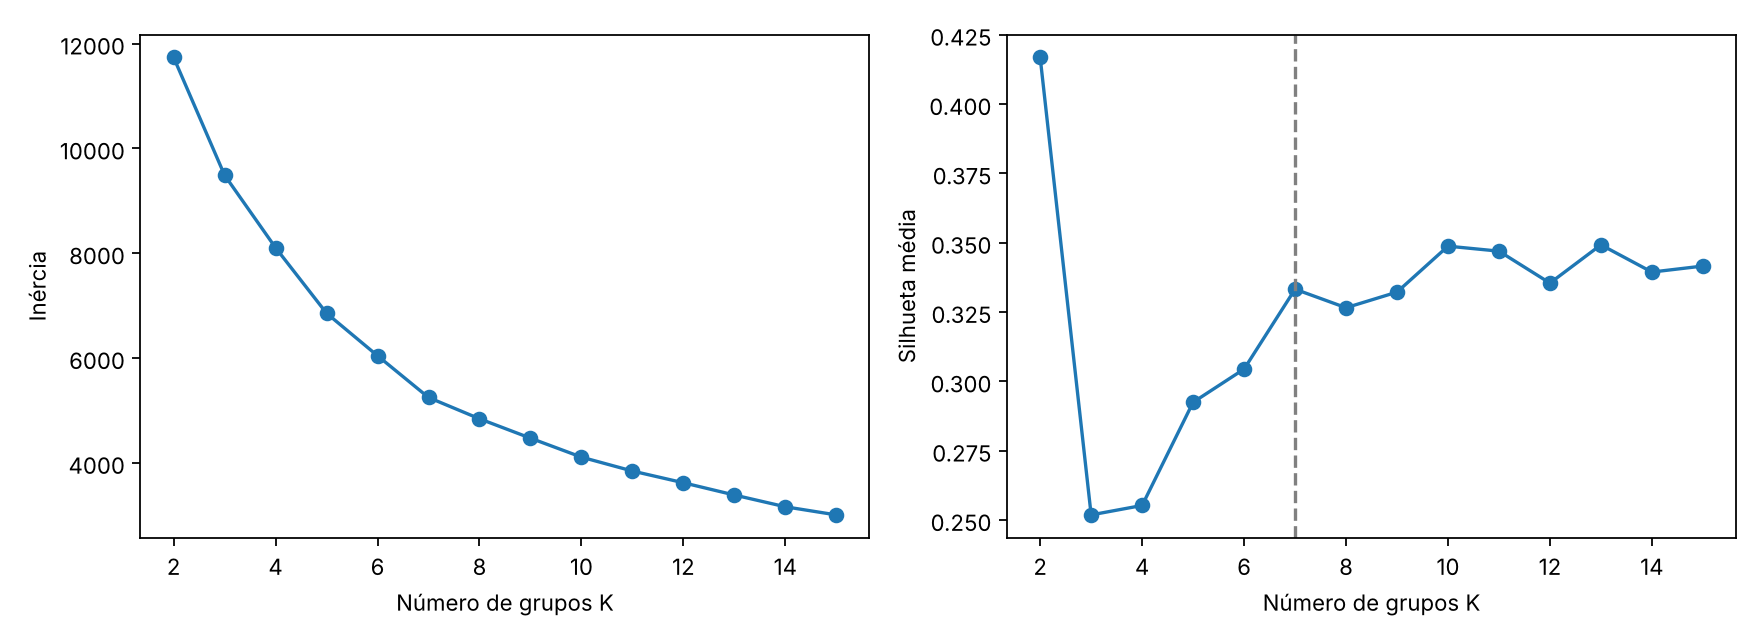

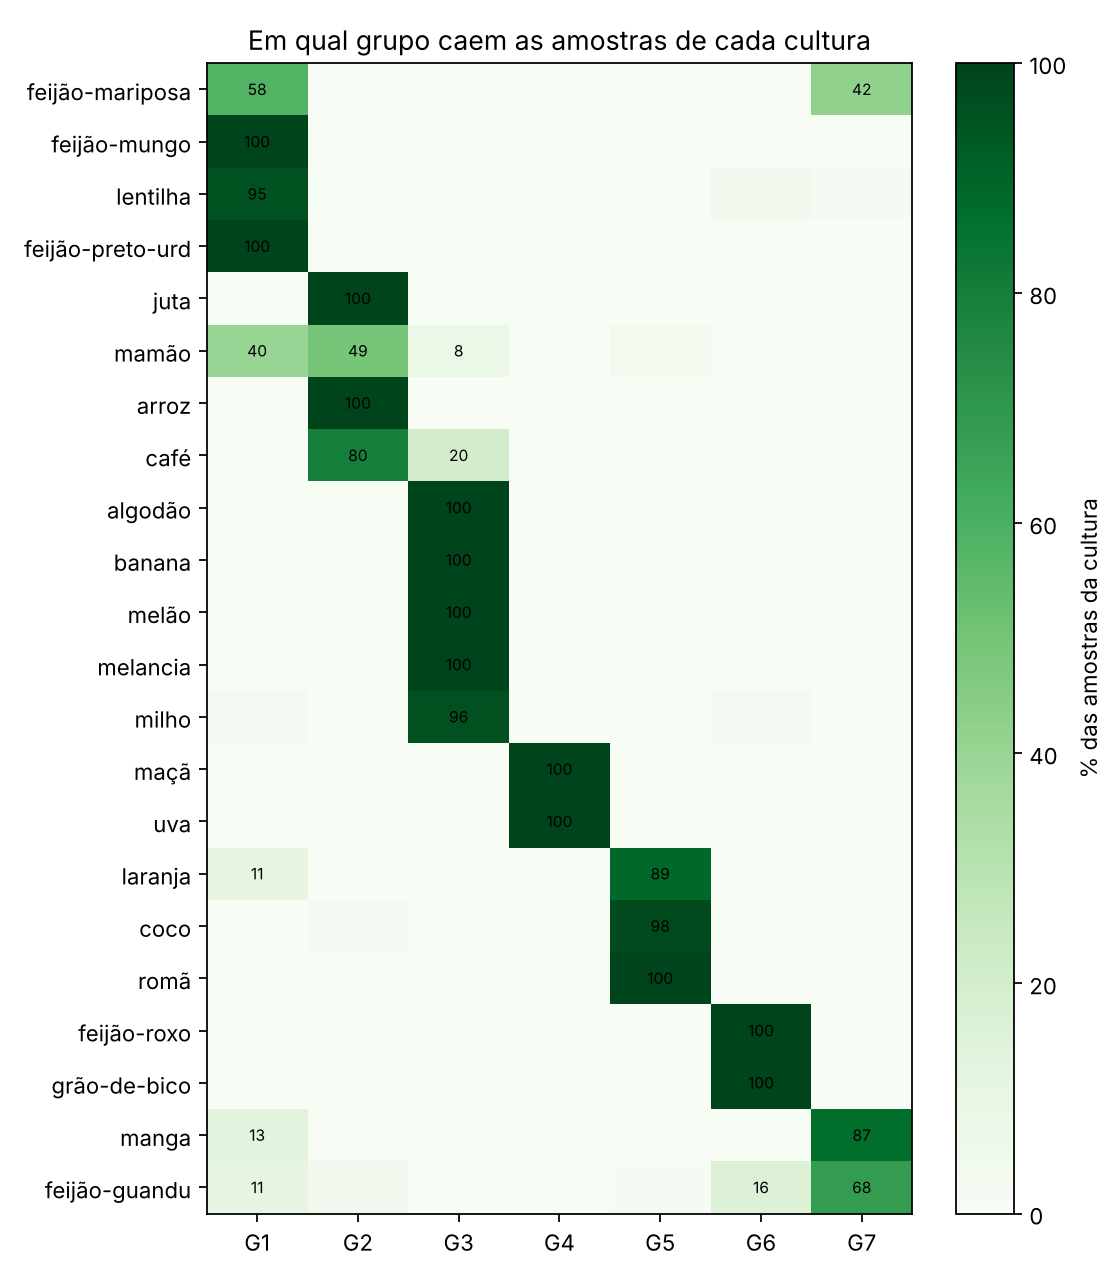

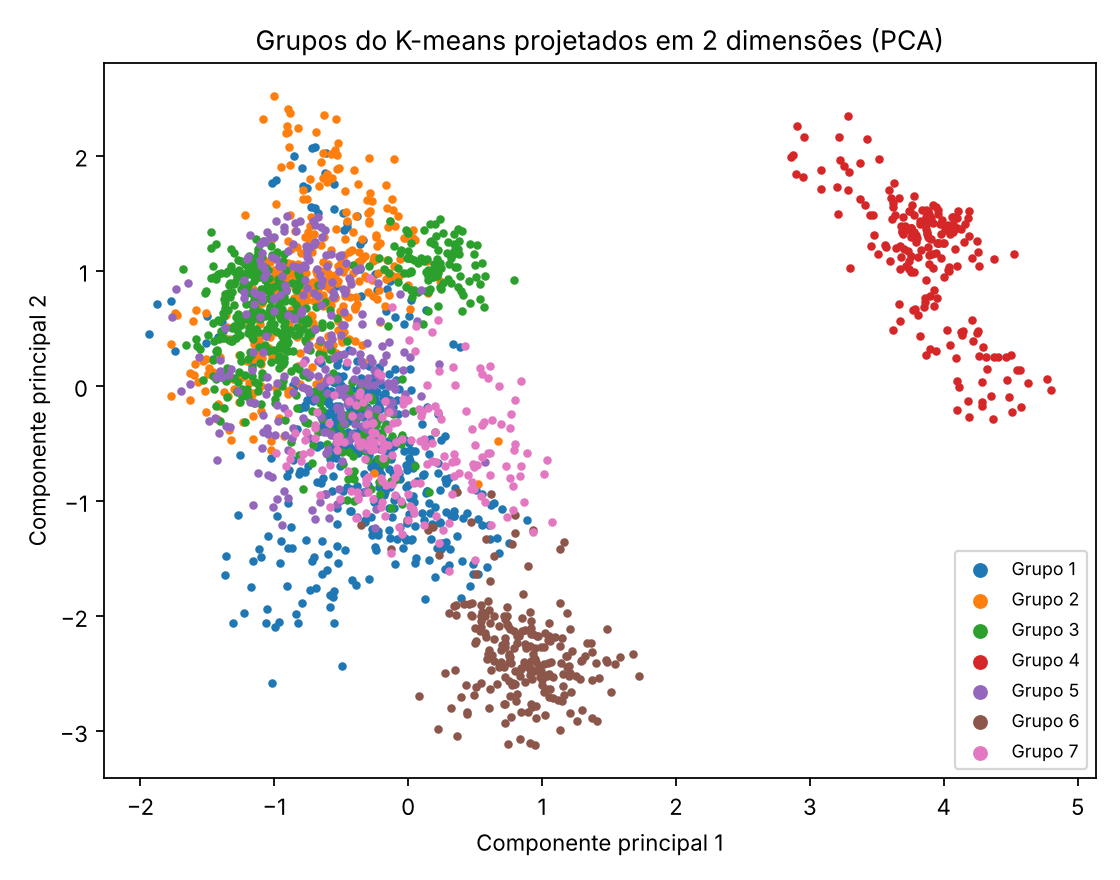

In [31]:
display(Image('resultados/kmeans_escolha_k.png', width=650))
display(Image('resultados/kmeans_composicao.png', width=650))
display(Image('resultados/kmeans_pca.png', width=650))